# 03 - Tuning (Optuna) dan evaluasi final
Alur yang menjaga test set tetap bersih:
1. **Tuning** LightGBM dengan Optuna memakai 3-fold cross-validation **di train set saja**.
2. Latih model final dengan parameter terbaik (early stopping memakai validation set).
3. Evaluasi **sekali** di test set, dibandingkan dengan LightGBM tanpa tuning.
4. Cek kalibrasi probabilitas dan tabel decile (lift), lalu simpan model.

Test set tidak dipakai untuk memilih parameter apa pun.

In [1]:
import json
import sys
import warnings
from pathlib import Path
from time import time

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import optuna
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.calibration import calibration_curve

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "docker-compose.yml").exists())
sys.path.append(str(ROOT))

from src.data import load_model_table, prepare, split

warnings.filterwarnings("ignore", message=".*eval_set.*")
sns.set_theme(style="whitegrid")
MODELS_DIR = ROOT / "models"
MODELS_DIR.mkdir(exist_ok=True)

X, y = prepare(load_model_table())
X_train, X_valid, X_test, y_train, y_valid, y_test = split(X, y)
print(X_train.shape, X_valid.shape, X_test.shape)

(215257, 165) (46127, 165) (46127, 165)


## 1. Tuning dengan Optuna
Objective: rata-rata ROC-AUC dari 3-fold stratified CV di train set. Study disimpan di file SQLite (`models/optuna_lgbm.db`),
jadi kalau kernel mati atau notebook ditutup, menjalankan cell ini lagi **melanjutkan** study yang sama sampai total `N_TRIALS`.

In [2]:
N_TRIALS = 30   # total percobaan; naikkan kalau waktu cukup

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
folds = list(skf.split(X_train, y_train))

def objective(trial):
    params = dict(
        n_estimators=2000,
        learning_rate=trial.suggest_float("learning_rate", 0.02, 0.1, log=True),
        num_leaves=trial.suggest_int("num_leaves", 15, 127),
        min_child_samples=trial.suggest_int("min_child_samples", 20, 300),
        subsample=trial.suggest_float("subsample", 0.6, 1.0),
        subsample_freq=1,
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
        reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
        metric="auc", random_state=42, n_jobs=-1, verbose=-1,
    )
    scores, iterations = [], []
    for train_idx, val_idx in folds:
        model = lgb.LGBMClassifier(**params)
        model.fit(X_train.iloc[train_idx], y_train.iloc[train_idx],
                  eval_set=[(X_train.iloc[val_idx], y_train.iloc[val_idx])],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
        scores.append(model.best_score_["valid_0"]["auc"])
        iterations.append(model.best_iteration_)
    trial.set_user_attr("mean_best_iteration", int(np.mean(iterations)))
    return float(np.mean(scores))

study = optuna.create_study(
    study_name="lgbm_credit_risk",
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42),
    storage=f"sqlite:///{(MODELS_DIR / 'optuna_lgbm.db').as_posix()}",
    load_if_exists=True,
)
remaining = max(0, N_TRIALS - len(study.trials))
print(f"Sudah ada {len(study.trials)} percobaan, menjalankan {remaining} lagi ...")
start = time()
study.optimize(objective, n_trials=remaining)
print(f"Selesai. Waktu sesi ini: {(time() - start) / 60:.1f} menit")
print(f"CV ROC-AUC terbaik: {study.best_value:.4f}")
study.best_params

[I 2026-11-17 14:21:25,285] A new study created in RDB with name: lgbm_credit_risk


Sudah ada 0 percobaan, menjalankan 30 lagi ...


[I 2026-11-17 14:22:05,614] Trial 0 finished with value: 0.782196348257712 and parameters: {'learning_rate': 0.03654452355213248, 'num_leaves': 122, 'min_child_samples': 225, 'subsample': 0.8394633936788146, 'colsample_bytree': 0.4936111842654619, 'reg_alpha': 0.004207053950287938, 'reg_lambda': 0.0017073967431528124}. Best is trial 0 with value: 0.782196348257712.
[I 2026-11-17 14:22:26,582] Trial 1 finished with value: 0.7758381112523435 and parameters: {'learning_rate': 0.0806234057607385, 'num_leaves': 82, 'min_child_samples': 218, 'subsample': 0.608233797718321, 'colsample_bytree': 0.9819459112971965, 'reg_alpha': 2.1368329072358767, 'reg_lambda': 0.0070689749506246055}. Best is trial 0 with value: 0.782196348257712.
[I 2026-11-17 14:23:05,364] Trial 2 finished with value: 0.7840126248893924 and parameters: {'learning_rate': 0.02679909904436604, 'num_leaves': 35, 'min_child_samples': 105, 'subsample': 0.8099025726528951, 'colsample_bytree': 0.6591670111852694, 'reg_alpha': 0.01461

Selesai. Waktu sesi ini: 19.0 menit
CV ROC-AUC terbaik: 0.7851


{'learning_rate': 0.023213133628180387,
 'num_leaves': 34,
 'min_child_samples': 67,
 'subsample': 0.6759497725351191,
 'colsample_bytree': 0.41922889357114795,
 'reg_alpha': 0.08811823404294981,
 'reg_lambda': 2.7723362270409555}

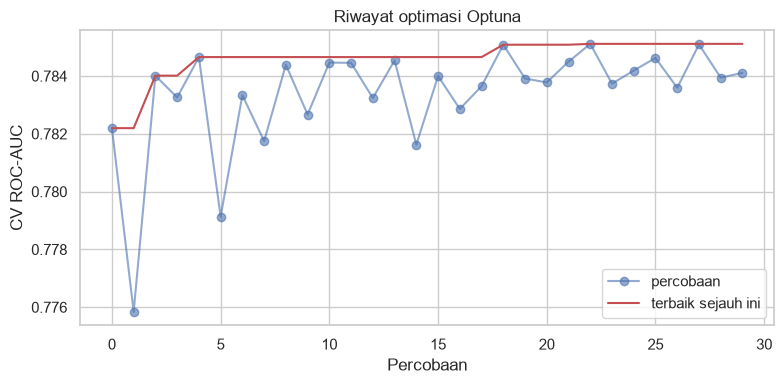

In [3]:
values = [t.value for t in study.trials if t.value is not None]
plt.figure(figsize=(8, 4))
plt.plot(values, "o-", alpha=0.6, label="percobaan")
plt.plot(np.maximum.accumulate(values), "r-", label="terbaik sejauh ini")
plt.xlabel("Percobaan")
plt.ylabel("CV ROC-AUC")
plt.title("Riwayat optimasi Optuna")
plt.legend()
plt.tight_layout()
plt.show()

## 2. Model final vs model tanpa tuning
Keduanya memakai early stopping di validation set. Test set baru disentuh di cell ini, sekali, untuk kedua model.

In [4]:
BASE = dict(n_estimators=2000, subsample_freq=1, metric="auc", random_state=42, n_jobs=-1, verbose=-1)
baseline_params = dict(learning_rate=0.05, num_leaves=31, min_child_samples=100,
                       subsample=0.8, colsample_bytree=0.7, reg_lambda=1.0)
tuned_params = dict(study.best_params)

def fit(params):
    model = lgb.LGBMClassifier(**BASE, **params)
    model.fit(X_train, y_train, eval_set=[(X_valid, y_valid)],
              callbacks=[lgb.early_stopping(100, verbose=False)])
    return model

baseline = fit(baseline_params)
tuned = fit(tuned_params)

rows = []
for name, model in [("LightGBM tanpa tuning", baseline), ("LightGBM hasil tuning", tuned)]:
    for split_name, Xs, ys in [("valid", X_valid, y_valid), ("test", X_test, y_test)]:
        p = model.predict_proba(Xs)[:, 1]
        rows.append({"model": name, "data": split_name,
                     "roc_auc": round(roc_auc_score(ys, p), 4),
                     "pr_auc": round(average_precision_score(ys, p), 4),
                     "brier": round(brier_score_loss(ys, p), 4),
                     "pohon": model.best_iteration_})
final_table = pd.DataFrame(rows)
final_table

,model,data,roc_auc,pr_auc,brier,pohon
0,LightGBM tanpa tuning,valid,0.7844,0.2829,0.0659,571
1,LightGBM tanpa tuning,test,0.7882,0.2829,0.0659,571
2,LightGBM hasil tuning,valid,0.7885,0.2860,0.0657,1253
3,LightGBM hasil tuning,test,0.7913,0.2845,0.0657,1253


Brier score adalah rata-rata kuadrat selisih antara probabilitas prediksi dan hasil sebenarnya (makin kecil makin baik).
Selisih kecil antara baseline dan hasil tuning itu normal: pada data tabular, tuning biasanya hanya menambah sedikit.

## 3. Kalibrasi probabilitas (test set)
Kalau model bilang risiko 20%, apakah sekitar 20% nasabah itu benar-benar gagal bayar?

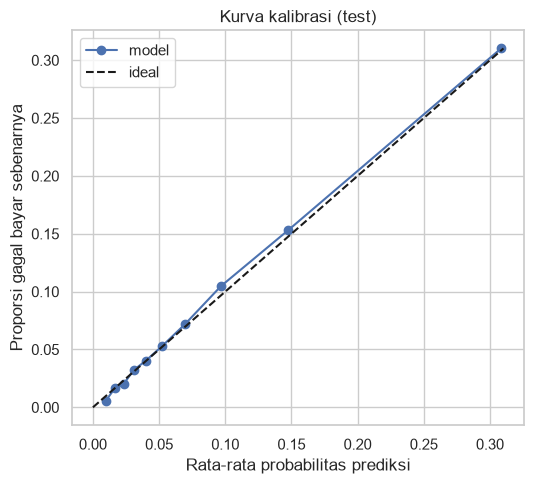

In [5]:
proba_test = tuned.predict_proba(X_test)[:, 1]
frac_pos, mean_pred = calibration_curve(y_test, proba_test, n_bins=10, strategy="quantile")

plt.figure(figsize=(5.5, 5))
plt.plot(mean_pred, frac_pos, "o-", label="model")
plt.plot([0, max(mean_pred.max(), frac_pos.max())], [0, max(mean_pred.max(), frac_pos.max())], "k--", label="ideal")
plt.xlabel("Rata-rata probabilitas prediksi")
plt.ylabel("Proporsi gagal bayar sebenarnya")
plt.title("Kurva kalibrasi (test)")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Tabel decile dan lift (test set)
Nasabah diurutkan dari risiko prediksi tertinggi lalu dibagi 10 kelompok sama besar. Decile 1 = 10% nasabah paling berisiko.
`lift` = default rate kelompok dibagi default rate rata-rata. `kumulatif_tertangkap_%` = berapa persen dari seluruh gagal bayar yang sudah tercakup sampai decile itu.

In [6]:
def decile_table(y_true, proba):
    d = pd.DataFrame({"y": y_true.values, "p": proba})
    d["decile"] = pd.qcut(d["p"].rank(method="first", ascending=False), 10, labels=range(1, 11))
    t = d.groupby("decile", observed=True).agg(
        nasabah=("y", "size"), gagal_bayar=("y", "sum"), rata_prediksi=("p", "mean"))
    t["default_rate_%"] = (t["gagal_bayar"] / t["nasabah"] * 100).round(2)
    t["lift"] = (t["default_rate_%"] / (y_true.mean() * 100)).round(2)
    t["kumulatif_tertangkap_%"] = (t["gagal_bayar"].cumsum() / t["gagal_bayar"].sum() * 100).round(1)
    t["rata_prediksi"] = t["rata_prediksi"].round(3)
    return t

deciles = decile_table(y_test, proba_test)
deciles

,nasabah,gagal_bayar,rata_prediksi,default_rate_%,lift,kumulatif_tertangkap_%
decile,,,,,,
1,4613,1431,0.308,31.02,3.84,38.4
2,4613,707,0.148,15.33,1.90,57.4
3,4612,483,0.097,10.47,1.30,70.4
4,4613,331,0.069,7.18,0.89,79.3
5,4613,244,0.052,5.29,0.66,85.8
6,4612,186,0.040,4.03,0.50,90.8
7,4613,148,0.031,3.21,0.40,94.8
8,4612,92,0.023,1.99,0.25,97.3
9,4613,76,0.017,1.65,0.20,99.3


## 5. Simpan model dan parameter
Model disimpan untuk tahap SHAP dan API. Pohon, daftar fitur, dan level kategori ikut tersimpan di dalam file model.

In [7]:
joblib.dump(tuned, MODELS_DIR / "lgbm_final.joblib")

summary = {
    "best_params": tuned_params,
    "cv_roc_auc_best": study.best_value,
    "n_trials": len(study.trials),
    "n_trees": int(tuned.best_iteration_),
    "metrics": final_table.to_dict(orient="records"),
}
(MODELS_DIR / "best_params.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("Tersimpan:", [p.name for p in MODELS_DIR.iterdir()])

Tersimpan: ['best_params.json', 'lgbm_final.joblib', 'optuna_lgbm.db']


## Catatan temuan
- **Tuning:** 30 percobaan Optuna (3-fold CV di train set) menghasilkan CV ROC-AUC 0,7851.
  Dibanding LightGBM tanpa tuning, ROC-AUC naik dari 0,7844 ke 0,7885 (valid) dan dari
  0,7882 ke 0,7913 (test), kenaikan kecil seperti lazimnya pada data tabular.
- **Generalisasi:** CV, valid, dan test berdekatan (0,785 / 0,789 / 0,791); tidak ada tanda
  overfit ke validation set.
- **Kalibrasi:** probabilitas prediksi mendekati proporsi gagal bayar sebenarnya (decile 1:
  prediksi 30,8%, aktual 31,0%) walau tanpa bobot kelas. Brier 0,0657 vs 0,0742 untuk
  menebak rata-rata.
- **Lift:** 10% nasabah paling berisiko memiliki default rate 31,0% (3,84x rata-rata) dan
  mencakup 38,4% dari semua gagal bayar; 30% teratas mencakup 70,4%. 30% nasabah paling aman
  hanya berisi 5,2% dari gagal bayar.